In [1]:
import os, sys, json, random, time, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from sklearn.metrics import accuracy_score, f1_score

sns.set_theme(style="whitegrid")

try:                                           # running in Google Colab
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = "/content/drive/MyDrive/SER"
except ImportError:                            # running locally from the notebooks/ folder
    ROOT = ".."
assert os.path.isdir(ROOT), f"Folder not found: {ROOT}. Create MyDrive/SER and upload the files (see instructions above)."
sys.path.insert(0, ROOT)
DATA = f"{ROOT}/data"
OUT = f"{ROOT}/cnn_outputs"
os.makedirs(OUT, exist_ok=True)

from ser_audio import EMOTIONS, N_MELS, N_FRAMES
from ser_cnn import SERCNN, spec_augment, save_checkpoint, load_checkpoint

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch", torch.__version__, "| device:", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "NO GPU")
if device.type != "cuda":
    print("WARNING: no GPU. In Colab use Runtime > Change runtime type > T4 GPU. (CPU works but is slow.)")

from sklearn.metrics import confusion_matrix, classification_report, precision_recall_fscore_support
EVAL = f"{OUT}/eval"
os.makedirs(EVAL, exist_ok=True)

Mounted at /content/drive
torch 2.14.1+cpu | device: cpu | NO GPU


In [2]:
summary = json.load(open(f"{OUT}/final_summary.json"))
assert not summary["quick_dry_run"], "cnn_best.pt comes from the QUICK dry run. Re-run notebook 06 with QUICK = False first."
print("Model chosen on validation data:", summary["chosen_run"], "| seed", summary["chosen_seed"])
print("Config:", summary["config"])

X = np.load(f"{DATA}/X_logmel_norm.npy")
labels = pd.read_csv(f"{DATA}/labels.csv")
norm_mean, norm_std = np.load(f"{DATA}/norm_stats.npy")
assert X.shape[0] == len(labels)

model, ckpt = load_checkpoint(f"{OUT}/cnn_best.pt", device)
assert abs(ckpt["norm_mean"] - float(norm_mean)) < 1e-4 and abs(ckpt["norm_std"] - float(norm_std)) < 1e-4, \
    "the checkpoint was trained with different normalization statistics than data/norm_stats.npy"

is_test = (labels["split"] == "test").values
test = labels[is_test].reset_index(drop=True)
assert sorted(test["actor"].unique()) == [1, 9, 12, 17, 19], "wrong test actors"
assert len(test) == 300, "unexpected number of test clips"
print("\nTest clips:", len(test), "| actors:", sorted(test["actor"].unique()))
print(test["emotion"].value_counts().reindex(EMOTIONS).to_dict())

X_te = torch.from_numpy(X[is_test][:, None, :, :]).float().to(device)
y_true = test["label"].values

Model chosen on validation data: no_specaug | seed 1
Config: {'channels': [32, 64, 128, 128], 'dropout': 0.3, 'lr': 0.001, 'weight_decay': 0.0001, 'specaug': False, 'label_smoothing': 0.0}

Test clips: 300 | actors: [np.int64(1), np.int64(9), np.int64(12), np.int64(17), np.int64(19)]
{'neutral': 20, 'calm': 40, 'happy': 40, 'sad': 40, 'angry': 40, 'fearful': 40, 'disgust': 40, 'surprised': 40}


## 3. Predict on the test set

In [3]:
@torch.no_grad()
def predict_probs(m, xs, batch=64):
    m.eval()
    return torch.cat([torch.softmax(m(xs[i:i + batch]), dim=1) for i in range(0, len(xs), batch)]).cpu().numpy()

probs = predict_probs(model, X_te)                 # (300, 8)
y_pred = probs.argmax(axis=1)
print("predictions:", probs.shape)

predictions: (300, 8)


## 4. Metrics

- **Accuracy:** share of clips predicted correctly.
- **Precision (macro):** for each emotion, of the clips predicted as that emotion how many were right; averaged over the 8 emotions.
- **Recall (macro):** for each emotion, of the real clips of that emotion how many were found; averaged over the 8 emotions.
- **Macro-F1:** average of the per-emotion F1 scores (F1 = combination of precision and recall). Every emotion counts equally, so the smaller neutral class is not ignored.

In [4]:
acc = accuracy_score(y_true, y_pred)
p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
_, _, f1w, _ = precision_recall_fscore_support(y_true, y_pred, average="weighted", zero_division=0)
row = pd.DataFrame([{"model": "CNN", "accuracy": acc, "precision_macro": p, "recall_macro": r, "f1_macro": f1, "f1_weighted": f1w}])
row.to_csv(f"{EVAL}/model_comparison_row.csv", index=False)
json.dump({k: float(v) for k, v in row.iloc[0].items() if k != "model"}, open(f"{EVAL}/metrics.json", "w"), indent=2)
print(row.round(3).to_string(index=False))
print(f"\nChance level = {1/len(EMOTIONS):.3f}")

model  accuracy  precision_macro  recall_macro  f1_macro  f1_weighted
  CNN     0.557            0.555         0.566     0.544        0.547

Chance level = 0.125


## 5. Per-emotion report

In [5]:
rep = classification_report(y_true, y_pred, labels=list(range(len(EMOTIONS))), target_names=EMOTIONS,
                            output_dict=True, zero_division=0)
rep_df = pd.DataFrame(rep).T.round(3)
rep_df.to_csv(f"{EVAL}/classification_report_CNN.csv")
rep_df

,precision,recall,f1-score,support
neutral,0.400,0.700,0.509,20.000
calm,0.548,0.850,0.667,40.000
happy,0.472,0.425,0.447,40.000
sad,0.455,0.250,0.323,40.000
angry,0.605,0.575,0.590,40.000
fearful,0.537,0.550,0.543,40.000
disgust,0.718,0.700,0.709,40.000
surprised,0.704,0.475,0.567,40.000
accuracy,0.557,0.557,0.557,0.557
macro avg,0.555,0.566,0.544,300.000


## 6. Confusion matrix

Rows = the true emotion, columns = what the CNN predicted. The diagonal is correct predictions. The right-hand plot shows each row as a percentage (the recall of that emotion).

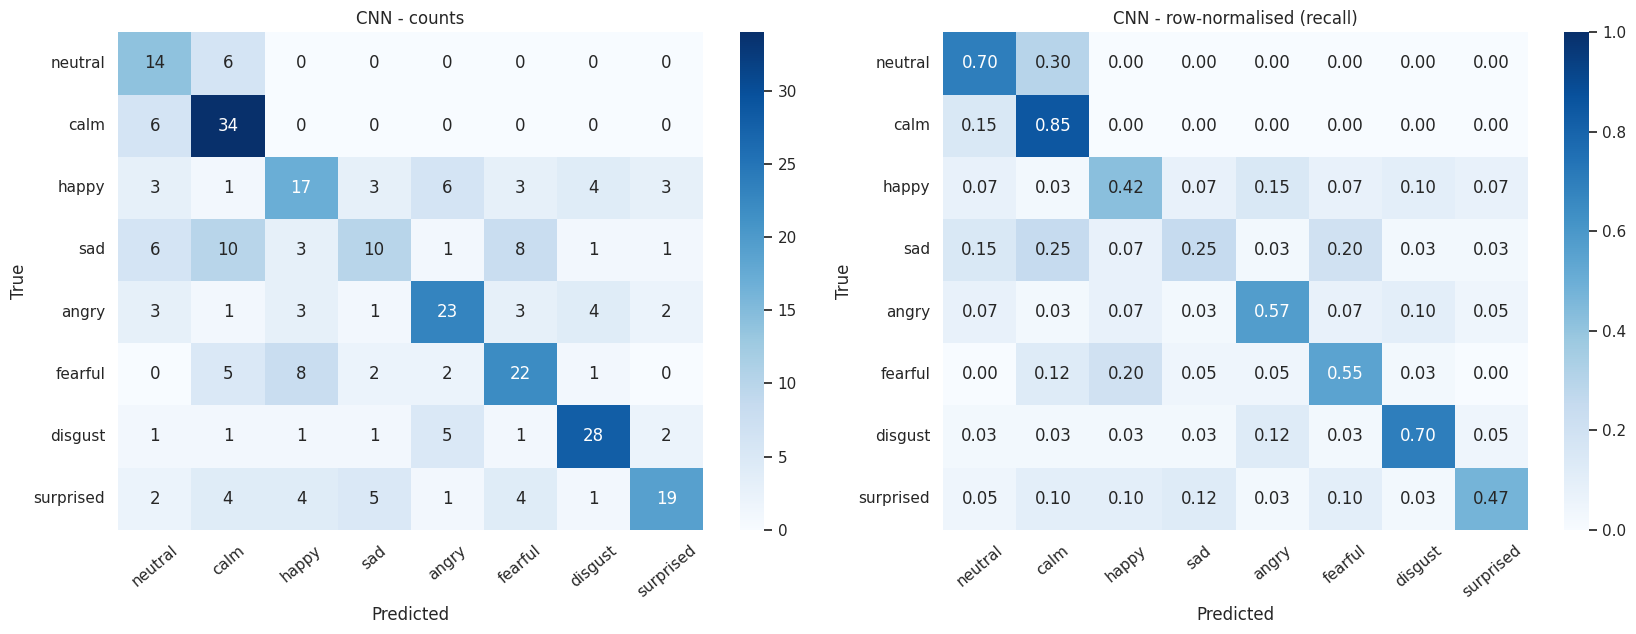

In [6]:
cm = confusion_matrix(y_true, y_pred, labels=list(range(len(EMOTIONS))))
cmn = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
pd.DataFrame(cm, index=EMOTIONS, columns=EMOTIONS).to_csv(f"{EVAL}/confusion_matrix_CNN.csv")

fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=EMOTIONS, yticklabels=EMOTIONS, ax=axes[0])
axes[0].set_title("CNN - counts")
sns.heatmap(cmn, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, xticklabels=EMOTIONS, yticklabels=EMOTIONS, ax=axes[1])
axes[1].set_title("CNN - row-normalised (recall)")
for a in axes:
    a.set_xlabel("Predicted"); a.set_ylabel("True"); a.tick_params(axis="x", rotation=40)
plt.tight_layout(); plt.savefig(f"{EVAL}/confusion_matrix_CNN.png", dpi=140); plt.show()

## 7. Error analysis



In [7]:
pairs = [(EMOTIONS[i], EMOTIONS[j], int(cm[i, j]), cm[i, j] / max(cm[i].sum(), 1))
         for i in range(8) for j in range(8) if i != j and cm[i, j] > 0]
top = pd.DataFrame(sorted(pairs, key=lambda t: -t[2])[:8], columns=["true", "predicted", "clips", "share_of_true_class"]).round(3)
top.to_csv(f"{EVAL}/top_confusions.csv", index=False)
print("Most frequent confusions:"); print(top.to_string(index=False))

pred = test[["filename", "actor", "gender", "intensity"]].copy()
pred["true"] = [EMOTIONS[i] for i in y_true]
pred["pred"] = [EMOTIONS[i] for i in y_pred]
pred["correct"] = (y_true == y_pred)
pred["confidence"] = probs.max(axis=1)
for i, e in enumerate(EMOTIONS):
    pred[f"prob_{e}"] = probs[:, i]
pred.to_csv(f"{EVAL}/predictions_test.csv", index=False)

by_actor = pred.groupby(["actor", "gender"])["correct"].mean().round(3).reset_index(name="accuracy")
by_gender = pred.groupby("gender")["correct"].mean().round(3)
by_intensity = pred.groupby("intensity")["correct"].mean().round(3)
print("\nAccuracy per test actor:"); print(by_actor.to_string(index=False))
print("\nBy gender:", by_gender.to_dict(), "| by intensity:", by_intensity.to_dict())
print("Mean confidence when correct: %.3f | when wrong: %.3f" % (pred.loc[pred.correct, "confidence"].mean(), pred.loc[~pred.correct, "confidence"].mean()))
by_actor.to_csv(f"{EVAL}/accuracy_by_actor.csv", index=False)

Most frequent confusions:
   true predicted  clips  share_of_true_class
    sad      calm     10                0.250
    sad   fearful      8                0.200
fearful     happy      8                0.200
neutral      calm      6                0.300
   calm   neutral      6                0.150
  happy     angry      6                0.150
    sad   neutral      6                0.150
fearful      calm      5                0.125

Accuracy per test actor:
 actor gender  accuracy
     1   male     0.583
     9   male     0.383
    12 female     0.700
    17   male     0.533
    19   male     0.583

By gender: {'female': 0.7, 'male': 0.521} | by intensity: {'normal': 0.506, 'strong': 0.614}
Mean confidence when correct: 0.551 | when wrong: 0.454


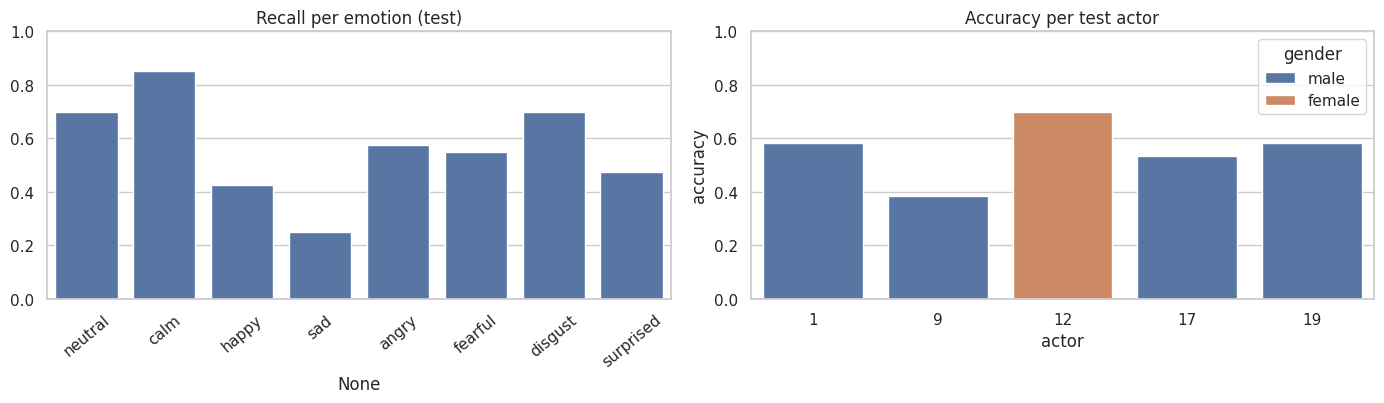

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
recall = pd.Series({e: rep[e]["recall"] for e in EMOTIONS})
sns.barplot(x=recall.index, y=recall.values, ax=axes[0], color="#4C72B0"); axes[0].set_ylim(0, 1)
axes[0].set_title("Recall per emotion (test)"); axes[0].tick_params(axis="x", rotation=40)
sns.barplot(data=by_actor, x="actor", y="accuracy", hue="gender", ax=axes[1], dodge=False); axes[1].set_ylim(0, 1)
axes[1].set_title("Accuracy per test actor")
plt.tight_layout(); plt.savefig(f"{EVAL}/error_analysis.png", dpi=140); plt.show()

In [9]:
rows = []
for s in [r["seed"] for r in summary["seeds"]]:
    m, _ = load_checkpoint(f"{OUT}/cnn_seed{s}.pt", device)
    pr = predict_probs(m, X_te).argmax(1)
    rows.append({"seed": s, "chosen": s == summary["chosen_seed"], "test_accuracy": accuracy_score(y_true, pr),
                 "test_macro_f1": f1_score(y_true, pr, average="macro")})
seed_df = pd.DataFrame(rows).round(3)
seed_df.to_csv(f"{EVAL}/seed_variability.csv", index=False)
print(seed_df.to_string(index=False))
print(f"\nmean +/- std over seeds: accuracy {seed_df.test_accuracy.mean():.3f} +/- {seed_df.test_accuracy.std():.3f}, "
      f"macro-F1 {seed_df.test_macro_f1.mean():.3f} +/- {seed_df.test_macro_f1.std():.3f}")

 seed  chosen  test_accuracy  test_macro_f1
    0   False          0.517          0.481
    1    True          0.557          0.544
    2   False          0.513          0.516

mean +/- std over seeds: accuracy 0.529 +/- 0.024, macro-F1 0.514 +/- 0.032
